In [58]:
# Essential libraries and tools
import os
from typing import TypedDict
from typing import Literal
from dotenv import load_dotenv

In [59]:
from langgraph.graph import StateGraph
from langgraph.graph import END                     # For building LangGraph workflows
from langchain_community.tools.tavily_search import TavilySearchResults  # Tavily search tool
from langchain.tools import WikipediaQueryRun                  # Wikipedia tool wrapper
from langchain.utilities import WikipediaAPIWrapper
from langchain_google_genai import ChatGoogleGenerativeAI      # Gemini LLM wrapper

In [60]:
load_dotenv()

True

In [61]:
# Define Shared State Between Nodes
class RouterState(TypedDict):
    input: str                    # User's input query
    selected_tool: Literal["wikipedia", "tavily"]  # Tool to use (selected by Tool Router)
    output: str                   # Final output after tool executes

In [62]:
# Initialize Search Tools
# Wikipedia Tool (static encyclopedic content)
wiki_tool = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())

In [63]:
# Tavily Tool
tavily_tool = TavilySearchResults()

In [64]:
# Gemini LLM Setup (used as intelligent Tool Router)
llm = ChatGoogleGenerativeAI(model="gemini-2.5-pro", temperature=0.9)

In [65]:
# Tool Router Agent
# Determines which tool (Wikipedia or Tavily) should handle the user's query
def tool_router_agent(state: RouterState) -> RouterState:
    query = state["input"]

    prompt = f"""
    You are a smart tool selector agent.

    If the input is a general topic like a famous person, place, event — choose 'wikipedia'.
    If it's a trending topic, product comparison, recent or niche info — choose 'tavily'.

    Just return one word: 'wikipedia' or 'tavily'.

    Input: {query}
    """

    # LLM decides the best tool
    answer = llm.invoke(prompt).content.strip().lower()
    print(f"ToolRouter selected: {answer}")

    # Tool selection logic with fallback to tavily
    if "wiki" in answer:
        state["selected_tool"] = "wikipedia"
    elif "tavily" in answer:
        state["selected_tool"] = "tavily"
    else:
        state["selected_tool"] = "tavily"  # fallback

    return state

In [66]:
# Wikipedia Node
# Executes search using Wikipedia for general/static topics
def wikipedia_node(state: RouterState) -> RouterState:
    query = state["input"]
    print(f"Wikipedia Searching: {query}")
    result = wiki_tool.run(query)
    state["output"] = result if result else "No Wikipedia result"
    return state

In [67]:
# Tavily Node
# Executes search using Tavily for real-time or product/niche queries
def tavily_node(state: RouterState) -> RouterState:
    query = state["input"]
    print(f"Tavily Searching: {query}")
    result = tavily_tool.run(query)

    # Handle Tavily result format (list or string)
    if isinstance(result, list) and result:
        content = result[0].get("content", "")
        state["output"] = content if content else "No content in Tavily"
    elif isinstance(result, str):
        state["output"] = result
    else:
        state["output"] = "Tavily returned no valid result"

    return state

In [68]:
# Initialize LangGraph Builder
builder = StateGraph(RouterState)

In [69]:
# Register Nodes (Functions/Agents)
builder.add_node("tool_router", tool_router_agent)
builder.add_node("wiki_tool", wikipedia_node)
builder.add_node("tavily_tool", tavily_node)

In [71]:
# Define Entry Point
builder.set_entry_point("tool_router")

In [72]:
# Dynamic Conditional Edge Routing
# Based on tool_router_agent's decision, route to the correct tool node
builder.add_conditional_edges("tool_router", lambda state: state["selected_tool"], {
    "wikipedia": "wiki_tool",
    "tavily": "tavily_tool"
})

In [ ]:
# Mark both tool nodes as ending points
builder.add_edge("wiki_tool", END)
builder.add_edge("tavily_tool", END)

In [74]:
# Compile the LangGraph into an executable graph object
graph = builder.compile()

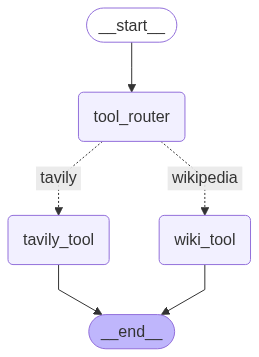

In [75]:
from IPython.display import Image
from IPython.display import display

display(Image(graph.get_graph().draw_mermaid_png()))

In [76]:
# Sample Queries
# One is general, the other is current/product-based
example1 = {"input": "What is quantum computing?", "selected_tool": "", "output": ""}
example2 = {"input": "Best electric cars in 2025", "selected_tool": "", "output": ""}

In [77]:
# Run Graph with Example 1
res1 = graph.invoke(example1)
print("\n Wikipedia-based Output:\n", res1["output"])

ToolRouter selected: wikipedia
Wikipedia Searching: What is quantum computing?

 Wikipedia-based Output:
 Page: Quantum computing
Summary: A quantum computer is a computer that exploits quantum mechanical phenomena. On small scales, physical matter exhibits properties of both particles and waves, and quantum computing takes advantage of this behavior using specialized hardware. Classical physics cannot explain the operation of these quantum devices, and a scalable quantum computer could perform some calculations exponentially faster than any modern "classical" computer. Theoretically a large-scale quantum computer could break some widely used encryption schemes and aid physicists in performing physical simulations; however, the current state of the art is largely experimental and impractical, with several obstacles to useful applications.
The basic unit of information in quantum computing, the qubit (or "quantum bit"), serves the same function as the bit in classical computing. However

In [78]:
# ✅ Run Graph with Example 2
res2 = graph.invoke(example2)
print("\nTavily-based Output:\n", res2["output"])

ToolRouter selected: tavily
Tavily Searching: Best electric cars in 2025

Tavily-based Output:
 Image 23Trucks

Volvo XC90Image 24Image 25Hybrids

Image 26Vans

Image 27Electric

Image 28Luxury

Image 29Sports Cars

Image 30Convertibles

Browse all models

Advertisement

### Frequently Asked Questions

What is the best electric car?

The best electric car is the 2025 Hyundai Ioniq 6, with an overall score of 8.9 out of 10. The best luxury electric car is the 2025 Lucid Air, with an overall score of 9.3 out of 10.

What is the best electric SUV? [...] Electric CarsLuxury Electric CarsElectric SUVsLuxury Electric SUVsElectric Pickup Trucks

### Electric Cars »

Image 2 ### #1 2025 Hyundai Ioniq 6 The 2025 Hyundai Ioniq 6 has a terrific driving range, it’s a blast to drive, and it’s packed with features. However, it has less cargo space than many rivals, and its relatively high price diminishes its value proposition. Read more » 8.9 SCORE $37,850 - $54,600 MSRP 111-151 City / 94-120 Hwy [